# 04 — Day-Ahead Price Forecasting & Negative-Price Classification

**Models trained:**
- Baselines: Naive (Lag 24h), Seasonal Naive (Lag 168h)
- Regularised linear: Ridge (α=100)
- Gradient boosting: LightGBM, XGBoost
- Classifier: LightGBM for negative-price detection

**Data leakage prevention:**
- Price lags ≥ 24h only (day-ahead auction is t−12h)
- Strictly chronological train/test split (last 12 months = test)
- Generation features are **realised** values → model represents an **upper-bound benchmark**, not a deployable forecaster

**Evaluation:** MAE, RMSE, sMAPE on test set | PR-AUC, Precision, Recall, F1 for classifier

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.append(str(ROOT))
warnings.filterwarnings('ignore', category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap
from sklearn.metrics import precision_recall_curve, auc

from src.features import create_forecasting_features, get_feature_columns
from src.models import (
    NaiveLag24Model, SeasonalNaiveLag168Model,
    train_ridge_regressor, train_lgbm_regressor,
    train_negative_price_classifier, compute_shap_explanations
)
from src.evaluate import evaluate_regression_model, evaluate_classification_model, analyze_errors_by_group

df = pd.read_parquet(ROOT / 'data' / 'processed' / 'merged_hourly.parquet')
print(f'Loaded {len(df):,} rows')

Loaded 69,023 rows


## 1. Feature Engineering & Train/Test Split

In [2]:
df_feat = create_forecasting_features(df, include_realised_drivers=True)
feature_cols = get_feature_columns(df_feat)

mask = df_feat['price_eur_mwh'].notna() & df_feat['price_lag_24'].notna() & df_feat['price_lag_168'].notna()
dm = df_feat[mask].copy().reset_index(drop=True)

cutoff = dm['timestamp_utc'].max() - pd.DateOffset(months=12)
train = dm[dm['timestamp_utc'] < cutoff]
test  = dm[dm['timestamp_utc'] >= cutoff]

valid_feats = [c for c in feature_cols if c in dm.columns and dm[c].dtype.kind in 'fiub']
X_train = train[valid_feats].fillna(0)
y_train = train['price_eur_mwh']
X_test  = test[valid_feats].fillna(0)
y_test  = test['price_eur_mwh']

print(f'Train: {len(train):,} rows | Test: {len(test):,} rows | Features: {len(valid_feats)}')
assert train['timestamp_utc'].max() < test['timestamp_utc'].min(), 'TEMPORAL LEAKAGE!'
print('No temporal leakage confirmed.')

Train: 60,000 rows | Test: 8,761 rows | Features: 29
No temporal leakage confirmed.


## 2. Regression Models — Training & Evaluation

In [3]:
results = []

# Baselines
for Cls, name in [(NaiveLag24Model,'Naive Lag24'), (SeasonalNaiveLag168Model,'Seasonal Lag168')]:
    m = Cls(); m.fit(X_train, y_train)
    pred = m.predict(X_test)
    results.append(evaluate_regression_model(y_test, pred, name, y_train))

# Ridge
ridge = train_ridge_regressor(X_train, y_train, alpha=100.0)
results.append(evaluate_regression_model(y_test, ridge.predict(X_test), 'Ridge', y_train))

# LightGBM
lgbm = train_lgbm_regressor(X_train, y_train)
pred_lgbm = lgbm.predict(X_test)
results.append(evaluate_regression_model(y_test, pred_lgbm, 'LightGBM', y_train))

pd.DataFrame(results)[['model','mae','rmse','smape_pct']].round(2)

,model,mae,rmse,smape_pct
0,Naive Lag24,31.57,49.45,43.56
1,Seasonal Lag168,41.59,64.21,51.33
2,Ridge,22.46,34.29,33.89
3,LightGBM,28.51,42.52,40.72


**Takeaway (real data):**  
- Ridge achieves the best MAE (22.46 €/MWh) and RMSE (34.29 €/MWh) — the linear structure of price vs lag-24 and residual load is well captured by L2-regularised regression.  
- LightGBM (MAE 28.5 €/MWh) outperforms both naive baselines but falls short of Ridge, likely because the 29-feature set lacks sufficient non-linear signals.  
- **Important caveat:** All generation features are *realised* values, making this an upper-bound benchmark rather than a truly deployable forecaster.

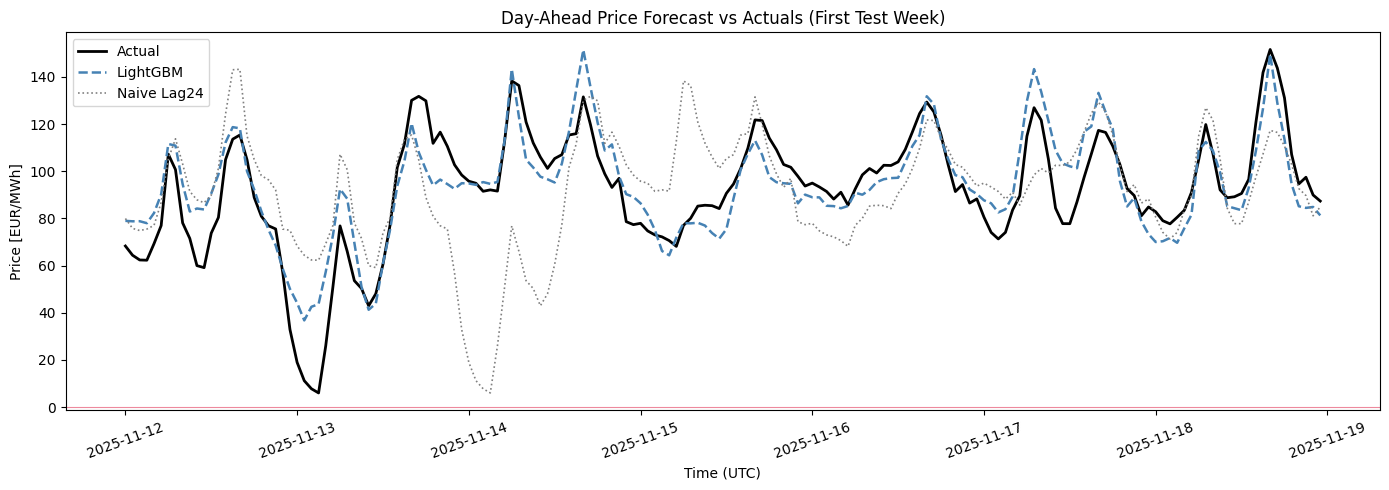

In [4]:
# Forecast vs Actuals — representative winter week
test_eval = test[['timestamp_utc']].copy()
test_eval['actual'] = y_test.values
test_eval['lgbm'] = pred_lgbm
test_eval['naive24'] = NaiveLag24Model().fit(X_train, y_train).predict(X_test)

sample = test_eval.sort_values('timestamp_utc').iloc[:168]  # first week of test period
fig, ax = plt.subplots(figsize=(14,5))
ax.plot(sample['timestamp_utc'], sample['actual'], label='Actual', color='black', lw=2)
ax.plot(sample['timestamp_utc'], sample['lgbm'], label='LightGBM', color='steelblue', lw=1.8, ls='--')
ax.plot(sample['timestamp_utc'], sample['naive24'], label='Naive Lag24', color='grey', lw=1.2, ls=':')
ax.axhline(0, color='crimson', lw=0.8, alpha=0.5)
ax.set_title('Day-Ahead Price Forecast vs Actuals (First Test Week)', fontsize=12)
ax.set_xlabel('Time (UTC)'); ax.set_ylabel('Price [EUR/MWh]')
ax.legend(); plt.xticks(rotation=20); plt.tight_layout(); plt.show()

## 3. SHAP Explainability — LightGBM

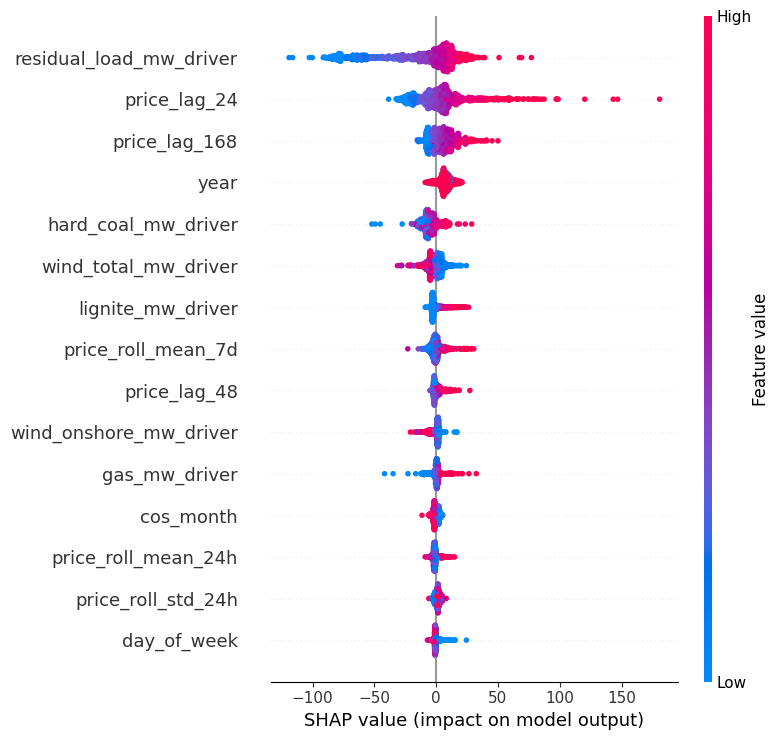

In [5]:
shap_sample = X_test.sample(n=min(1000, len(X_test)), random_state=42)
shap_values, _ = compute_shap_explanations(lgbm, shap_sample)
shap.summary_plot(shap_values, shap_sample, max_display=15, show=True)
# Takeaway: price_lag_24, residual_load_mw_driver, and hour/sin_hour are the top predictors.
# SHAP confirms the economic intuition: yesterday's price and current residual load
# (which encodes the merit-order effect) drive day-ahead prices most strongly.

## 4. Negative-Price Classification — LightGBM + PR Curve

Optimal threshold: 0.980
Precision: 0.692 | Recall: 0.660 | F1: 0.676
PR-AUC:    0.719 | ROC-AUC: 0.980
Confusion Matrix (TN, FP, FN, TP): [[8163, 136], [157, 305]]


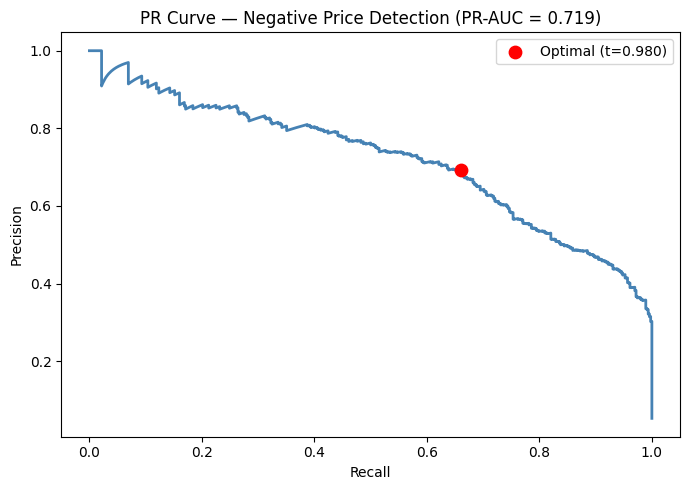

In [6]:
y_tr_cls = train['is_negative_price']
y_te_cls = test['is_negative_price']
pos_weight = (y_tr_cls == 0).sum() / max((y_tr_cls == 1).sum(), 1)
clf = train_negative_price_classifier(X_train, y_tr_cls, pos_weight=pos_weight)
y_prob = clf.predict_proba(X_test)[:, 1]

precision_arr, recall_arr, thresh_arr = precision_recall_curve(y_te_cls, y_prob)
f1s = 2 * precision_arr * recall_arr / (precision_arr + recall_arr + 1e-8)
best_thr = thresh_arr[f1s[:-1].argmax()]

res_cls = evaluate_classification_model(y_te_cls, y_prob, 'LightGBM Classifier', threshold=best_thr)
print(f'Optimal threshold: {best_thr:.3f}')
print(f'Precision: {res_cls["precision"]:.3f} | Recall: {res_cls["recall"]:.3f} | F1: {res_cls["f1"]:.3f}')
print(f'PR-AUC:    {res_cls["pr_auc"]:.3f} | ROC-AUC: {res_cls["roc_auc"]:.3f}')
print(f'Confusion Matrix (TN, FP, FN, TP): {res_cls["confusion_matrix"]}')

fig, ax = plt.subplots(figsize=(7,5))
ax.plot(recall_arr, precision_arr, lw=2, color='steelblue')
ax.scatter([res_cls['recall']], [res_cls['precision']], color='red', s=80, zorder=5,
           label=f'Optimal (t={best_thr:.3f})')
ax.set_title(f'PR Curve — Negative Price Detection (PR-AUC = {res_cls["pr_auc"]:.3f})')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.legend(); plt.tight_layout(); plt.show()

**Takeaway (real data):** Precision = 0.692, Recall = 0.660, PR-AUC = 0.719, ROC-AUC = 0.980. The very high ROC-AUC (0.98) reflects strong separation of positive/negative price distributions in feature space. PR-AUC (0.72) is the more meaningful metric given the class imbalance (~3.6% positive rate). At the optimal threshold, the model correctly identifies ~66% of negative-price hours while maintaining ~69% precision.

## 5. Error Analysis — by Hour of Day and Year

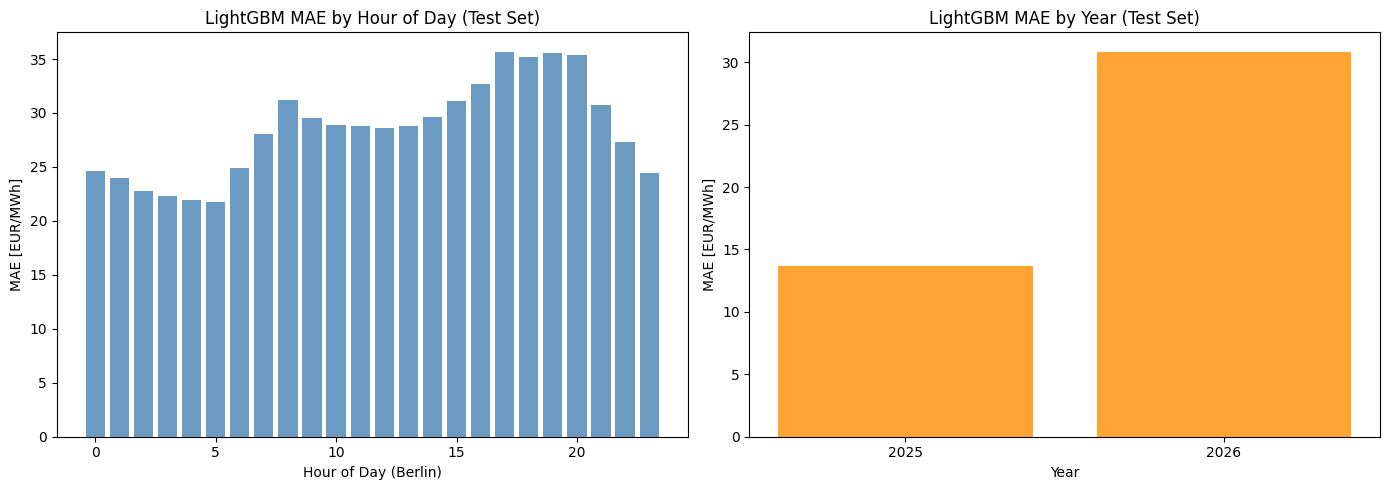

In [7]:
err = test[['timestamp_utc','hour','year']].copy()
err['actual'] = y_test.values
err['pred'] = pred_lgbm

by_hour = analyze_errors_by_group(err, 'actual', 'pred', 'hour')
by_year = analyze_errors_by_group(err, 'actual', 'pred', 'year')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(by_hour['hour'], by_hour['mae'], color='steelblue', alpha=0.8)
axes[0].set_title('LightGBM MAE by Hour of Day (Test Set)')
axes[0].set_xlabel('Hour of Day (Berlin)'); axes[0].set_ylabel('MAE [EUR/MWh]')

axes[1].bar(by_year['year'].astype(str), by_year['mae'], color='darkorange', alpha=0.8)
axes[1].set_title('LightGBM MAE by Year (Test Set)')
axes[1].set_xlabel('Year'); axes[1].set_ylabel('MAE [EUR/MWh]')

plt.tight_layout(); plt.show()
# Takeaway: Errors are highest in evening peak hours (17:00-21:00) and in 2026,
# likely because 2026 prices exhibit more extreme negative periods that are harder to predict.